# E102 · Which way does the bias go? Hidden targeting, reach and the sign of a propensity estimate

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify (a sequel to E101) |
| **Data** | Real: the **Criteo Uplift Prediction Dataset v2.1** (Diemert et al. 2018; CC BY-NC-SA 4.0), the same 300,000-user sample as E101. The **45,100 control users** saw no ads, so each one's observed site visit **is** their no-ad outcome; we keep their real features and real visits and simulate only who gets an ad |
| **You will learn** | The bias of any propensity estimate of the effect on the exposed as one number - the gap between the exposed users' **true and imputed no-ad baseline** - and why its **sign** is the sign of the link between hidden targeting and the outcome · a **placebo** design on real rows: a known true effect, so every estimate's error is its bias · a **threshold model** of ad delivery, the closed-form gap $\phi(t)/[\Phi(t)(1-\Phi(t))]$ at the standardised bar $t$ and where it fails on real data · **positive and negative bias** from retargeting, suppression lists, prospecting and ad avoiders · how bias, **overlap** and the **effective sample** of the unexposed move as **reach** goes from 4% to 95% · a full **Bayesian propensity analysis** (cut posterior, Bayesian bootstrap) that confidently reports a working campaign as useless · a **sensitivity model** in PyMC and **E-values** that cannot tell the sign · what this means for a brand lift study |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: a BLAS pool per chain would fight over the cores

import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
from scipy import special, stats
from scipy.optimize import brentq

from pymc_challenges import data

RANDOM_SEED = 102
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()

BLUE, ORANGE, AQUA, PURPLE, RED = "#2a78d6", "#eb6834", "#1baf7a", "#8c5ac8", "#c8384e"
INK, MUTED, LIGHT = "#222222", "#8a8984", "#d9d8d3"
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}")

PyMC 6.3.2, ArviZ 1.3.0


## The setting

E101 graded a propensity analysis of an ad campaign against the randomised experiment hidden in the same
file. The analysis was done by the book - a Bayesian propensity model, balance within 0.1 on every feature,
four estimators that agreed - and it **overstated** the effect on the exposed: it imputed a no-ad visit rate
of 14.6% for the exposed users where the experiment said 20.3%, so the ads looked 5 points more effective
than they were. The reason was selection: Criteo's campaign delivered its ads to active, interested users who
would have visited anyway, and twelve anonymised features captured only part of that. One caveat from E101
carries over: the 20.3% is the experiment *adjusted* for a small imbalance between its arms. Unadjusted, the
experiment says 12.75%, and against that the propensity analysis would *understate* the visit effect. For
conversions the overstatement holds either way (1.09% imputed against 2.60% adjusted and 2.18% unadjusted).
Even on real data, then, the sign of a bias can hinge on how the benchmark is computed. Below we use the
adjusted figure, E101's own benchmark, as the reference.

Two questions follow, and this notebook answers them. **What would it take for the bias to go the other
way**, so that a propensity analysis *understates* what the ads did? And **how does the bias change as a
campaign's reach grows**, so that the people left unexposed are more and more the hard-to-reach, media-light
corner of the audience?

Both have one root. Propensity scores (Rosenbaum & Rubin 1983) make the exposed and unexposed comparable on the
features we measured; whatever else decided who saw an ad is left in the comparison. Gordon,
Zettelmeyer, Bhargava & Chapsky (2019) found on 15 Facebook campaigns that the leftover error was usually an
overstatement, but not always, and that its size varied wildly between campaigns. Johnson, Lewis &
Nubbemeyer (2017) built ghost ads precisely so that advertisers would not have to guess. The direction of the
error is not a law of advertising; it is a property of how a particular campaign chose its audience, and the
arithmetic of that choice can be written down.

We cannot run new campaigns, but Criteo's file (Diemert et al. 2018) has a randomised **control arm**: 45,100
users in our sample who could not be shown the ads, so their observed visit is exactly their visit without ads.
We keep those users, their features and their visits, and **simulate only the exposure**: we decide, by a rule
we control, which of them "saw the ad".
Since an ad that was never shown changes nothing, the true effect on the exposed is exactly zero, and any
estimate a propensity analysis returns *is* its bias. To make the rule realistic, we hide one real feature
from the analyst and let the simulated ad server use what it knows - so the confounder's link to the outcome
is real, not assumed - and we turn two dials: how the hidden trait steers delivery, and the reach. A
sensitivity analysis in the spirit of VanderWeele & Ding (2017) then asks whether the data could have warned
us which way the error went.

| part | question | tool |
|---|---|---|
| A | What are the real rows, and what is hidden? | the control arm as the audience; f8's private information about visiting as the hidden trait |
| B | What decides the sign and the size of the bias? | the imputed baseline; a threshold model of delivery; the gap $\phi(t)/[\Phi(t)(1-\Phi(t))]$ |
| C | How do we measure bias? | a placebo campaign on real rows; IPW and AIPW with fast posterior-mode fits; replicated deliveries |
| D | When is the bias negative? | retargeting, prospecting, suppression lists, a retarget-then-prospect plan |
| E | What does reach do? | bias, overlap and effective sample size from 4% to 95% reach, against the theory |
| F | Would a careful Bayesian analysis notice? | a full PyMC propensity analysis of a negative-bias campaign with a real effect |
| G | Can the data tell the sign? | a PyMC sensitivity model and E-values in two mirror-image worlds |
| H | What should a brand lift study do? | the decision |

## A · Real rows, simulated delivery

In [2]:
data.describe("e101_criteo_uplift")
raw = np.load(data.path("e101_criteo_uplift"))
X = raw["X"].astype(float)
T = raw["treatment"].astype(int)
D_real = raw["exposure"].astype(int)
VISIT = raw["visit"].astype(float)
FEATS = [f"f{i}" for i in range(12)]
N = len(T)
ctl, tst = T == 0, T == 1
REACH_REAL = D_real[tst].mean()
print(f"\nsample: {N:,} users; control {ctl.sum():,} (visit rate {VISIT[ctl].mean():.4f}, "
      f"{int(VISIT[ctl].sum()):,} visitors, {int(raw['conversion'][ctl].sum())} conversions)")
print(f"test arm: {tst.sum():,} users, of whom {D_real[tst].sum():,} were shown an ad: the real campaign's reach "
      f"{REACH_REAL:.4f}")

e101_criteo_uplift: npz. A simple random sample of 300,000 of the 13,979,592 users in Criteo's pooled incrementality tests (randomised holdouts; several advertisers' tests sub-sampled to one treatment ratio): X (300000, 12) float32 anonymised features f0-f11 (float64 in the source), treatment (1 = test arm, randomised, ~85%), exposure (1 = the user was actually shown an ad; only possible in test), visit (visited the advertiser's site), conversion, row (row in the source). Plus EXACT full-data counts for the cells control / test-unexposed / test-exposed: cell_n, cell_visit, cell_conversion (3,), and per-cell feature sums cell_xsum, cell_xsq (3, 12); full-data sufficient statistics of a 91-column basis of the features' normal scores (1, r, r^2, pairwise products): basis_zz (arm, 91, 91), basis_zy (arm, outcome, 91), basis_cell_sum (3, 91); n_total, seed. Absolute rates are not the campaign's: Criteo down-sampled negatives non-uniformly.
  source: Criteo Uplift Prediction Dataset v2.1: Di

The **audience** for every simulated campaign is the control arm: 45,100 users with a visit rate of 3.7%.
They are a random sample of the people the real campaign could have reached, including the ones it would
have reached, so they are the right population to deliver pretend ads to. With 81 conversions among them,
conversions are too rare for this exercise, so we work with **visits** only. The test arm's 245,778 users who
were *not* shown an ad also visited without ads, but they are the audience minus the people the real campaign
chose, a selected group. We use them only for one auxiliary job below, learning what the hidden feature
knows, so that nothing about the hidden trait is learned from the very visits it will be compared with.

### A1 · The hidden trait

A realistic hidden confounder is a characteristic the ad server acts on and the analyst's file lacks - recent
site activity, purchase intent, how much time someone spends where the ads run. Criteo's features are
anonymised, but some of them carry exactly that kind of information about visiting. We **hide f8** from the
analyst, who keeps the other eleven. Hiding the raw feature would not do much on its own: Criteo's features are
random projections and overlap heavily, and the other eleven explain most of f8's variance (the first line
printed below). What matters is what f8 knows
about visiting **that the other eleven do not**. We measure it directly. On the test-unexposed users we fit
two logistic models of visiting, one with all twelve features and one without f8 (each feature as its
rank-based normal score and its square, as in E101), and take, for each control user, the difference of the
two linear predictors - the shift in their log-odds of visiting that only f8 reveals. We remove what the
eleven visible features can still predict of that shift and give the remainder normal scores. The result,
$u$, has mean 0 and sd 1 in the audience, is very nearly uncorrelated with the analyst's 22 terms, and is real
information about each user's visits.

In [3]:
def normal_scores(A):
    """Rank-based normal scores per column (ties share a rank)."""
    return np.column_stack([stats.norm.ppf((stats.rankdata(a) - 0.5) / len(a)) for a in A.T])


def fit_map(Z, y, prior_sd=0.5, a0=0.0, a_sd=1.5, iters=60):
    """Posterior mode of a logistic regression with N(a0, a_sd) intercept and N(0, prior_sd) slopes (Newton)."""
    Z1 = np.column_stack([np.ones(len(Z)), Z])
    prec = np.r_[1 / a_sd ** 2, np.full(Z.shape[1], 1 / prior_sd ** 2)]
    mu0 = np.r_[a0, np.zeros(Z.shape[1])]
    b = mu0.copy()
    for _ in range(iters):
        p = special.expit(Z1 @ b)
        g = Z1.T @ (y - p) - prec * (b - mu0)
        H = (Z1 * (p * (1 - p))[:, None]).T @ Z1 + np.diag(prec)
        step = np.linalg.solve(H, g)
        step *= min(1.0, 2.0 / max(np.abs(step).max(), 1e-12))    # damped: never move a log-odds by more than 2
        b += step
        if np.abs(step).max() < 1e-8:
            break
    return b


R = normal_scores(X)
Zall = np.column_stack([R, R ** 2])
Zall = (Zall - Zall.mean(0)) / Zall.std(0)                          # 24 standardised terms, as in E101
HIDDEN = 8
SEEN = [k for k in range(12) if k != HIDDEN]
SEEN_NAMES = [FEATS[k] for k in SEEN]
Zseen = Zall[:, SEEN + [12 + k for k in SEEN]]                      # the analyst's 22 terms

# what f8 knows about visiting beyond the other eleven: learned on test users who saw no ad
tu = tst & (D_real == 0)
a0_v = special.logit(VISIT[tu].mean())
b_all = fit_map(Zall[tu], VISIT[tu], a0=a0_v)
b_seen = fit_map(Zseen[tu], VISIT[tu], a0=a0_v)
shift = np.column_stack([np.ones(N), Zall]) @ b_all - np.column_stack([np.ones(N), Zseen]) @ b_seen

Zp = Zseen[ctl]                                                     # the audience: control users
Z1p = np.column_stack([np.ones(len(Zp)), Zp])
Y0 = VISIT[ctl]                                                     # their no-ad visits
n = len(Y0)
proj = np.linalg.lstsq(Z1p, shift[ctl], rcond=None)[0]
resid = shift[ctl] - Z1p @ proj
u = stats.norm.ppf((stats.rankdata(resid) - 0.5) / n)               # the hidden trait, N(0, 1) in the audience
beta_u = np.linalg.lstsq(np.column_stack([Z1p, u]), Y0, rcond=None)[0][-1]
m_seen = special.expit(Z1p @ fit_map(Zp, Y0, a0=special.logit(Y0.mean())))   # visit rate predicted from what is seen
f8 = R[ctl, HIDDEN]
r2_f8 = 1 - np.var(f8 - Z1p @ np.linalg.lstsq(Z1p, f8, rcond=None)[0]) / np.var(f8)
print(f"share of the variance of f8 itself (normal score) explained by the seen features: {r2_f8:.2f}")
print(f"hidden trait u: sd of the f8 log-odds shift {shift[ctl].std():.2f}, share not predictable from the "
      f"eleven seen features {resid.std() / shift[ctl].std():.2f}")
print(f"visits rise by {beta_u * 100:.2f} points per sd of u, holding the seen features fixed "
      f"(linear probability slope); corr(u, visit) {np.corrcoef(u, Y0)[0, 1]:.3f}")
dq = pd.qcut(u, 10, labels=False)
by_u = pd.DataFrame({"visit rate (%)": pd.Series(Y0).groupby(dq).mean() * 100,
                     "predicted from seen features (%)": pd.Series(m_seen).groupby(dq).mean() * 100,
                     "observed / predicted": pd.Series(Y0).groupby(dq).sum() / pd.Series(m_seen).groupby(dq).sum()})
by_u.index = [f"d{i + 1}" for i in range(10)]
print(by_u.round(2).T.to_string())

# does the REAL campaign act on u? its exposures in the test arm against the seen features and u
Z1t = np.column_stack([np.ones(tst.sum()), Zseen[tst]])
u_t = np.interp(shift[tst] - Z1t @ proj, np.sort(resid), np.sort(u))
b_real_u = fit_map(np.column_stack([Zseen[tst], u_t]), D_real[tst], a0=special.logit(REACH_REAL))
print(f"real campaign, test arm: log-odds of exposure per sd of u, given the seen features: {b_real_u[-1]:+.3f}")

share of the variance of f8 itself (normal score) explained by the seen features: 0.89
hidden trait u: sd of the f8 log-odds shift 0.86, share not predictable from the eleven seen features 0.83
visits rise by 2.37 points per sd of u, holding the seen features fixed (linear probability slope); corr(u, visit) 0.122
                                    d1    d2    d3    d4    d5    d6    d7    d8     d9    d10
visit rate (%)                    2.77  4.41  1.91  0.93  0.60  0.55  0.49  1.57  11.71  12.39
predicted from seen features (%)  5.83  7.43  2.72  1.32  1.02  0.94  0.78  2.31   9.38   5.63
observed / predicted              0.48  0.59  0.70  0.70  0.59  0.59  0.62  0.68   1.25   2.20


real campaign, test arm: log-odds of exposure per sd of u, given the seen features: +0.103


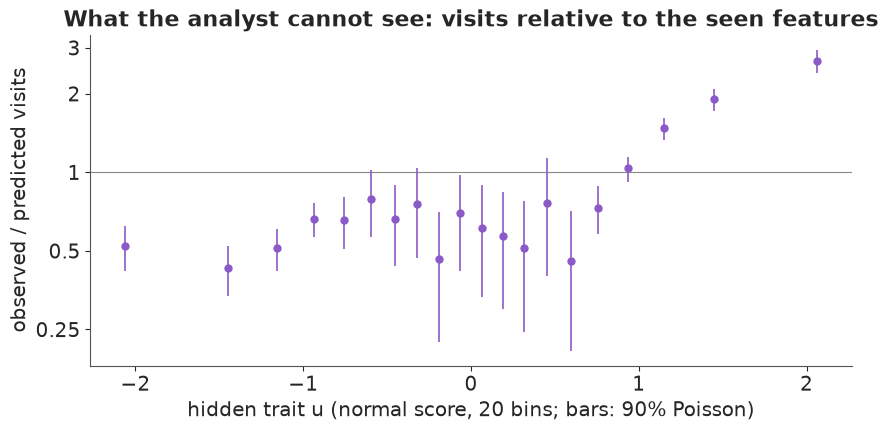

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
q20 = pd.qcut(u, 20, labels=False)
obs_ = pd.Series(Y0).groupby(q20).sum().values
exp_ = pd.Series(m_seen).groupby(q20).sum().values
mid = pd.Series(u).groupby(q20).mean().values
ratio = obs_ / exp_
err = np.sqrt(np.maximum(obs_, 1)) / exp_
ax.axhline(1, color=MUTED, lw=0.8)
ax.errorbar(mid, ratio, yerr=1.645 * err, fmt="o", color=PURPLE, ms=5, capsize=0, lw=1.2)
ax.set(xlabel="hidden trait u (normal score, 20 bins; bars: 90% Poisson)", ylabel="observed / predicted visits",
       title="What the analyst cannot see: visits relative to the seen features", yscale="log")
ax.set_yticks([0.25, 0.5, 1, 2, 3], labels=["0.25", "0.5", "1", "2", "3"])
ax.minorticks_off();

The part of the f8 shift that the other features cannot predict keeps 83% of its standard deviation, so most
of $u$ really is hidden. Its link to visiting is strong and **very uneven**. Holding the seen features fixed,
visits rise by about 2.4 points per standard deviation of $u$ on a base of 3.7%, but the table and the figure
show that this average hides a step. In the bottom eight deciles of $u$ users visit at half to seven tenths of
what their seen features predict; from about the 85th percentile the ratio climbs steeply, to 1.25 in the ninth
decile, 2.2 in the tenth and 2.7 in the top twentieth. Most of what f8 knows is "this person is about to
visit". In marketing language $u$ is **brand engagement** beyond what the file records, the residue of recent
activity and intent. Two facts about it matter below: its link with visits is positive, and it is convex,
concentrated in the top tail.

The real campaign barely uses it. Given the seen features, the test arm's real exposures move by only 0.10 in
log-odds per sd of $u$, so E101's bias did not come from f8 but from something neither we nor the file can see.
Here we decide how much the simulated ad server leans on $u$.

## B · The arithmetic of the bias

Write $Y(0)$ for a user's visit without ads, $D$ for exposure and $x$ for the features the analyst has. Every
propensity estimator of the effect on the exposed (ATT) - inverse-probability weighting, stratification,
outcome regression, doubly robust AIPW - reports the exposed users' observed rate minus an **imputed baseline**,
and with correct models and infinite data the imputed baseline is what unexposed users with the same $x$ did.
The estimator's error is therefore

$$\text{bias} = \mathbb{E}_{x \mid D=1}\Big[\,\mathbb{E}[Y(0) \mid D = 1, x] - \mathbb{E}[Y(0) \mid D = 0, x]\,\Big],$$

the gap, among people who look the same on paper, between what the exposed would have done and what the
unexposed did. It is zero when, given $x$, nothing that drives exposure also drives the outcome. When something
does - call it $u$ - the **sign** of the bias is the sign of their association given $x$: if delivery favours
high-$u$ users and high-$u$ users would visit more anyway, the imputed baseline is too low and the effect is
overstated (E101); if delivery favours low-$u$ users, or if high-$u$ users are kept out, the imputed baseline
is too high and the effect is **understated**, possibly to below zero.

To see how reach enters, model delivery as a **threshold**: a user is exposed when their media proneness clears
a bar set by the budget,

$$D = \mathbf{1}\{\eta(x) + \gamma u + \varepsilon > c\}, \qquad u, \varepsilon \sim N(0, 1),$$

where $\eta(x)$ is targeting on visible features, $\gamma u + \varepsilon$ is the hidden part of media
proneness (a share related to brand engagement, a share that is pure habit), and the bar $c$ fixes the reach.
Given $x$, the hidden part $v = (\gamma u + \varepsilon)/\sqrt{1+\gamma^2}$ is standard normal and correlated
$\rho = \gamma/\sqrt{1+\gamma^2}$ with $u$. With the local bar $t = (c - \eta(x))/\sqrt{1+\gamma^2}$, the
truncated-normal means give

$$\mathbb{E}[u \mid D=1, x] - \mathbb{E}[u \mid D=0, x] = \rho\,\Big[\frac{\phi(t)}{1-\Phi(t)} + \frac{\phi(t)}{\Phi(t)}\Big]
= \rho\,\frac{\phi(t)}{\Phi(t)\,\big(1-\Phi(t)\big)}.$$

If the outcome were linear in $u$ with slope $\beta_u$, the bias would be $\beta_u$ times this gap, averaged over
the exposed. Three things follow. The sign is the sign of $\gamma\beta_u$ and does not depend on the reach. The
size grows with $|\rho|$, how much of the hidden media proneness is brand engagement. And the gap, as a function
of the reach $r = 1 - \Phi(t)$, is **smallest at 50% and grows toward both ends**: at low reach the exposed are
an extreme tail, at high reach the unexposed are. The numbers for a single bar:

In [5]:
def gap_factor(r):
    """phi(t) / (Phi(t) (1 - Phi(t))) at reach r = 1 - Phi(t)."""
    t = stats.norm.isf(r)
    return stats.norm.pdf(t) / (r * (1 - r))


for r in (0.036, 0.05, 0.25, 0.5, 0.75, 0.95):
    t = stats.norm.isf(r)
    print(f"reach {r:5.3f}: E[v | exposed] {stats.norm.pdf(t) / r:+.2f}, E[v | unexposed] {-stats.norm.pdf(t) / (1 - r):+.2f},"
          f" gap {gap_factor(r):.2f}")

reach 0.036: E[v | exposed] +2.20, E[v | unexposed] -0.08, gap 2.28
reach 0.050: E[v | exposed] +2.06, E[v | unexposed] -0.11, gap 2.17
reach 0.250: E[v | exposed] +1.27, E[v | unexposed] -0.42, gap 1.69
reach 0.500: E[v | exposed] +0.80, E[v | unexposed] -0.80, gap 1.60
reach 0.750: E[v | exposed] +0.42, E[v | unexposed] -1.27, gap 1.69
reach 0.950: E[v | exposed] +0.11, E[v | unexposed] -2.06, gap 2.17


The gap in the hidden part of media proneness is 1.60 standard deviations at 50% reach and 2.17 at 5% or 95%.
As reach rises past one half, the exposed group's mean drifts toward zero (it is turning into the whole
audience) while the unexposed slide down the tail: at 95% reach they average 2.06 sd below the mean. That is
the intuition behind the question made exact - the comparison group becomes the media-light corner. Whether
that makes the *bias* bigger depends on what the media-light corner is like on the outcome, which a single
slope $\beta_u$ cannot say. With the convex link we just saw, the low end of $u$ looks much like its middle, so
we should expect the symmetric picture to break. The simulation shows how.

## C · A placebo campaign on real rows

The simulated ad server follows the threshold model exactly. Its visible targeting $\eta(x)$ is the **real
campaign's**: a logistic model of who was shown an ad in the test arm, on the eleven seen features, rescaled
from the logistic to the normal scale (divided by 1.7) so that it sits on the same scale as the unit-variance
noise. Then $\gamma$ sets how hidden media proneness relates to engagement: $\gamma > 0$ is retargeting-like
(media-heavy users are the engaged ones), $\gamma < 0$ is the opposite (the engaged are media-light, or are
being avoided). The bar $c$ is the quantile of the latent index that delivers the chosen reach.

The analyst then does what E101 did, with the eleven seen features: a logistic propensity model with the 22
normal-score terms, an outcome model of visiting among the unexposed, and two estimators of the effect on the
exposed,

$$\hat\tau_{\text{IPW}} = \bar Y_{D=1} - \frac{\sum_{D=0} w_i Y_i}{\sum_{D=0} w_i},\qquad
\hat\tau_{\text{AIPW}} = \overline{(Y - \hat m_0)}_{D=1} - \frac{\sum_{D=0} w_i (Y_i - \hat m_0(x_i))}{\sum_{D=0} w_i},
\qquad w_i = \frac{\hat e(x_i)}{1 - \hat e(x_i)}.$$

For the sweep we use **posterior modes** (a Newton solver with E101's N(0, 0.5) priors) rather than full
posteriors: several hundred campaigns times two models would take an hour of NUTS, and the question here is
the centre of each estimator, not its interval. Part F shows one full Bayesian analysis. Estimated
propensities are capped at 0.99, a common guard against a handful of unexposed users carrying the whole
weight. Each setting is replayed with **8 independent draws** of the noise $\varepsilon$, and **24** from 80%
reach up, where single campaigns scatter most, so we see the spread a single campaign would have. The true effect is zero, so every number below is a bias, in percentage points
of visits.

In [6]:
b_x =fit_map(Zseen[tst], D_real[tst], a0=special.logit(REACH_REAL))
eta = Z1p @ b_x
eta = (eta - eta.mean()) / 1.7                                      # visible targeting, on the probit scale
print(f"visible targeting eta(x): sd {eta.std():.2f} on the latent (unit-noise) scale")


def deliver(gamma, reach, rng_, exclude=None):
    """One simulated campaign: exposed = top `reach` share of eta(x) + gamma u + noise (never the excluded)."""
    L = eta + gamma * u + rng_.normal(size=n)
    if exclude is not None:
        L[exclude] = -np.inf
    return L > np.quantile(L, 1 - reach)


E_CAP = 0.99


def att_weights(eta_e):
    """ATT weights e / (1 - e) for the unexposed, with the propensity capped at 0.99."""
    e = np.minimum(special.expit(eta_e), E_CAP)
    return e / (1 - e)


def analyse(d, y=Y0, Z=Zp):
    """The analyst's propensity analysis with posterior-mode models: IPW and AIPW effect on the exposed."""
    d = d.astype(float)
    t, un = d == 1, d == 0
    w = att_weights(Z1p @ fit_map(Z, d, a0=special.logit(d.mean())))
    m0 =special.expit(Z1p @ fit_map(Z[un], y[un], a0=special.logit(max(y[un].mean(), 1e-4))))
    y1 = y[t].mean()
    ipw = y1 - np.average(y[un], weights=w[un])
    aipw = np.mean(y[t] - m0[t]) - np.average(y[un] - m0[un], weights=w[un])
    return {"IPW": ipw, "AIPW": aipw, "true baseline": Y0[t].mean(), "imputed baseline": y1 - aipw,
            "ESS": w[un].sum() ** 2 / (w[un] ** 2).sum(), "unexposed": int(un.sum()),
            "u gap": u[t].mean() - u[un].mean()}


GAMMAS = [-1.0, -0.5, 0.0, 0.5, 1.0]
REACHES = [REACH_REAL, 0.1, 0.2, 0.35, 0.5, 0.65, 0.8, 0.9, 0.95]
REPS = 8
reps_at = lambda r: 3 * REPS if r >= 0.8 else REPS                  # high reach is noisier: three times the replays
t0 = time.time()
rs = np.random.default_rng(RANDOM_SEED + 1)
sweep = pd.DataFrame([{"gamma": g, "reach": r, "rep": k, **analyse(deliver(g, r, rs))}
                      for g in GAMMAS for r in REACHES for k in range(reps_at(r))])
print(f"{len(sweep)} simulated campaigns analysed in {time.time() - t0:.0f} s")
summ = sweep.groupby(["gamma", "reach"]).agg(
    AIPW=("AIPW", "mean"), AIPW_sd=("AIPW", "std"), AIPW_se=("AIPW", "sem"), IPW=("IPW", "mean"),
    IPW_se=("IPW", "sem"),
    true_base=("true baseline", "mean"), imputed=("imputed baseline", "mean"),
    ESS=("ESS", "mean"), unexposed=("unexposed", "mean")).reset_index()
pp = summ.copy()
pp[["AIPW", "AIPW_sd", "AIPW_se", "IPW", "IPW_se", "true_base", "imputed"]] *= 100
print("gamma = 0 (delivery ignores u): mean bias in points by reach")
print(pp[pp.gamma == 0][["reach", "AIPW", "AIPW_sd", "IPW"]].round(2).T.to_string(header=False))

visible targeting eta(x): sd 0.84 on the latent (unit-noise) scale


600 simulated campaigns analysed in 32 s
gamma = 0 (delivery ignores u): mean bias in points by reach
reach    0.04  0.10  0.20  0.35  0.50  0.65  0.80  0.90  0.95
AIPW     0.35  0.16  0.03 -0.11 -0.23 -0.38  0.31  0.22  0.21
AIPW_sd  1.10  1.00  0.66  0.86  0.72  1.08  0.89  0.96  0.97
IPW      0.08 -0.10  0.31  0.17  0.86  1.15  1.39  1.28  1.55


The 600 campaigns take about half a minute. The first check is the null case. With $\gamma = 0$ the ad server
targets the seen features only, everything that drives delivery is in the analyst's file, and both estimators
should be right on average. AIPW is: its mean stays within 0.4 points of zero at every reach, against a spread
from one replay to the next of 0.7-1.1 points. IPW is right up to about 35% reach and then drifts up, to
+0.9 points at 50%, +1.2 at 65% and +1.6 at 95%, where 2,255 unexposed users must stand in for everyone else and the
propensity model's tail matters. Keep that drift in mind: it is model dependence, not confounding, and it will
come back. Whatever else appears below is the hidden trait's doing.

## D · The sign of the bias

Before sweeping reach, here is the menu of campaigns at the real campaign's reach, 3.6%, the setting of
E101. Alongside the $\gamma$ family we run a **suppression list**: the advertiser excludes its most engaged
users - recent visitors, existing customers - from the campaign, a routine instruction to stop paying for
people who would come anyway. We model it as the top 10% of $u$ never being exposed, with delivery otherwise
on the visible features alone.

In [7]:
supp = u > np.quantile(u, 0.9)
rs2 = np.random.default_rng(RANDOM_SEED + 2)
SUPP_REACH = [REACH_REAL, 0.1, 0.2, 0.35, 0.5, 0.65, 0.8]
supp_runs = pd.DataFrame([{"reach": r, "rep": k, **analyse(deliver(0.0, r, rs2, exclude=supp))}
                          for r in SUPP_REACH for k in range(REPS)])
menu = []
labels_g = {1.0: "retargeting, strong (gamma = +1)", 0.5: "retargeting (gamma = +0.5)",
            0.0: "visible targeting only (gamma = 0)", -0.5: "engaged are media-light (gamma = -0.5)",
            -1.0: "prospecting / ad avoiders (gamma = -1)"}
for g in [1.0, 0.5, 0.0, -0.5, -1.0]:
    s_ = sweep[(sweep.gamma == g) & (sweep.reach == REACH_REAL)]
    menu.append({"campaign": labels_g[g], "AIPW bias": s_.AIPW.mean(), "sd": s_.AIPW.std(),
                 "IPW bias": s_.IPW.mean(), "true baseline": s_["true baseline"].mean(),
                 "imputed baseline": s_["imputed baseline"].mean(), "u gap": s_["u gap"].mean()})
s_ = supp_runs[supp_runs.reach == REACH_REAL]
menu.append({"campaign": "suppression list (top 10% of u excluded)", "AIPW bias": s_.AIPW.mean(), "sd": s_.AIPW.std(),
             "IPW bias": s_.IPW.mean(), "true baseline": s_["true baseline"].mean(),
             "imputed baseline": s_["imputed baseline"].mean(), "u gap": s_["u gap"].mean()})
menu = pd.DataFrame(menu).set_index("campaign")
menu[["AIPW bias", "sd", "IPW bias", "true baseline", "imputed baseline"]] *= 100
print(f"reach {REACH_REAL:.3f} (the real campaign's); true effect 0; points of visits:")
print(menu.round(2).to_string())
E101_IMPUTED, E101_TRUE = 0.146, 0.203          # E101 part F: AIPW-imputed vs experimental no-ad visit rate
print(f"E101's real campaign: imputed {E101_IMPUTED:.1%} vs true {E101_TRUE:.1%} -> bias "
      f"{(E101_TRUE - E101_IMPUTED) * 100:+.1f} points ({(E101_TRUE - E101_IMPUTED) / E101_TRUE:.0%} of the baseline)")

reach 0.036 (the real campaign's); true effect 0; points of visits:
                                          AIPW bias    sd  IPW bias  true baseline  imputed baseline  u gap
campaign                                                                                                   
retargeting, strong (gamma = +1)               9.10  1.05      8.39          19.28             10.18   1.45
retargeting (gamma = +0.5)                     5.74  1.71      5.10          18.25             12.50   0.87
visible targeting only (gamma = 0)             0.35  1.10      0.08          16.01             15.66  -0.02
engaged are media-light (gamma = -0.5)        -4.46  0.81     -3.77          12.65             17.11  -0.88
prospecting / ad avoiders (gamma = -1)        -7.60  2.17     -9.16           9.78             17.38  -1.43
suppression list (top 10% of u excluded)      -1.92  1.06     -1.99          14.37             16.29  -0.31
E101's real campaign: imputed 14.6% vs true 20.3% -> bias +5.7 point

At the real campaign's reach the sign follows the targeting, as the arithmetic said it would. Delivery that
leans toward the hidden trait ($\gamma > 0$, retargeting-like) overstates the effect: by 5.7 points at
$\gamma = +0.5$ and 9.1 at $\gamma = +1$, because the analysis imputes a no-ad visit rate of 12.5% and 10.2%
for exposed users whose true rates are 18.3% and 19.3%. The $\gamma = +0.5$ campaign is nearly a replica of
E101's visit result: its imputed baseline is 31% too low, E101's was 28% too low against the adjusted
experiment, and its bias of 5.7 points matches E101's 5.7. A hidden trait carrying f8's private information,
leaned on moderately, is enough to reproduce E101's error with these users.

Flip the sign of $\gamma$ and the bias flips: **-4.5 points** at $\gamma = -0.5$ and **-7.6** at $\gamma = -1$.
The true effect is zero, so the analysis is reporting that the ads *reduced* visits by 4 to 8 points. The
imputed baseline is now too high (17.1% and 17.4% against true rates of 12.7% and 9.8%): the unexposed users
who look like the exposed on paper are the engaged ones the delivery passed over. The $\gamma = -1$ replays
also spread more (sd 2.2 points), because the propensity model pushes a few unexposed users toward the cap.
The **suppression list** gives -1.9 points: the comparison group contains exactly the people the advertiser
kept out for being likely to come anyway.

These are not exotic. Four real mechanisms produce a negative bias, and they live in different kinds of
campaign. The first is the last row of the table: **suppression lists and exclusion targeting**. Performance
advertisers routinely exclude recent visitors, existing customers or recent converters so as not to pay for sure
things, and the unexposed then hold the highest-baseline people in the audience. This is the everyday case in
direct-response display and search, Criteo's own world. The second is **prospecting and reach buys**, the
$\gamma < 0$ rows: campaigns built to find new customers - lookalike audiences that exclude the customer file,
"new to brand" segments, broad reach extensions - deliberately go to people with a low baseline and leave loyal
customers out.

The other two act through media habits rather than through the advertiser's lists. **Ad avoiders** - ad-blocker
users, people on ad-free subscription tiers, people who reach a brand through its app or e-mail - are hard to
reach with display, video and connected-TV ads, and they are often the brand's most engaged users; that is
$\gamma < 0$ on media proneness, with media-light, brand-heavy people on the unexposed side. And in **survey brand
lift for established brands**, where the outcome is awareness or consideration, the media-light respondents a
campaign misses (older, less online) can know a long-established brand better than the heavy online users it
reaches, so the measured lift shrinks. Retargeting and in-market targeting push the other way, as in E101; a real
campaign often carries several of these at once.

## E · What reach does

Now the second dial. For each $\gamma$ we sweep reach from the real campaign's 3.6% to 95% and draw the AIPW
bias, its replay-to-replay spread, and two theory curves. The dashed curve is the linear threshold formula of
part B, $\beta_u \rho\,\phi(t)/[\Phi(t)(1-\Phi(t))]$, averaged over the exposed with each user's own bar
$t = (c - \eta(x))/\sqrt{1+\gamma^2}$. The solid curve keeps the threshold model but replaces the straight line in
$u$ by the real, convex link: a logistic model of the audience's visits on the seen features plus a piecewise
linear function of $u$ (fitted with $u$ in hand, which only we have), integrated over $u$ for each user. Both
treat $u$ as independent of the seen features, which is only linearly true.

In [8]:
KN = np.quantile(u, [0.1, 0.3, 0.5, 0.7, 0.85, 0.95])
hinge = lambda v: np.column_stack([v] + [np.maximum(v - k, 0) for k in KN])
b_or = fit_map(np.column_stack([Zp, hinge(u)]), Y0, a0=special.logit(Y0.mean()), prior_sd=2.0)
eta_y = Z1p @ b_or[:Zp.shape[1] + 1]                                # oracle outcome model: seen part ...
UG = np.linspace(-4, 4, 81)
WG = stats.norm.pdf(UG) / stats.norm.pdf(UG).sum()
h_u = hinge(UG) @ b_or[Zp.shape[1] + 1:]                            # ... and the shape in u


def bar(gamma, r):
    """Each user's local bar t and exposure probability for reach r under the threshold model."""
    s = np.sqrt(1 + gamma ** 2)
    c = brentq(lambda c_: np.mean(stats.norm.sf((c_ - eta) / s)) - r, -30, 30)
    return c - eta, s


def theory(gamma, r):
    """(linear-formula bias, convex-link bias, gap in u) of the threshold model at reach r."""
    k, s = bar(gamma, r)
    t = k / s
    P = stats.norm.sf(t)
    gap = (gamma / s) * stats.norm.pdf(t) / np.clip(stats.norm.cdf(t) * P, 1e-300, None)
    lin = beta_u * np.sum(P * gap) / P.sum()
    num = 0.0
    for i in range(0, n, 5000):
        pd1 = stats.norm.cdf(gamma * UG[None, :] - k[i:i + 5000, None])        # P(exposed | u, x)
        m = special.expit(eta_y[i:i + 5000, None] + h_u[None, :])
        p1 = (pd1 * WG).sum(1)
        e1 = (m * pd1 * WG).sum(1) / p1
        e0 = (m * (1 - pd1) * WG).sum(1) / np.clip(1 - p1, 1e-300, None)
        num += np.sum(p1 * (e1 - e0))
    return lin, num / P.sum(), np.sum(P * gap) / P.sum()


RGRID = np.r_[REACH_REAL, np.round(np.linspace(0.05, 0.95, 19), 3)]
t0 = time.time()
th = pd.DataFrame([{"gamma": g, "reach": r, **dict(zip(["linear", "convex", "u gap"], theory(g, r)))}
                   for g in GAMMAS if g != 0 for r in RGRID])
print(f"theory curves in {time.time() - t0:.0f} s")
show = th[th.reach.isin([REACH_REAL, 0.5, 0.95])].copy()
show[["linear", "convex"]] *= 100
show = show.merge(pp[["gamma", "reach", "AIPW", "AIPW_sd", "IPW"]], on=["gamma", "reach"], how="left")
print(show.round(2).to_string(index=False))

theory curves in 9 s
 gamma  reach  linear  convex  u gap  AIPW  AIPW_sd   IPW
  -1.0   0.04   -3.34   -4.22  -1.41 -7.60     2.17 -9.16
  -1.0   0.50   -2.86   -3.44  -1.20 -3.53     0.50 -4.01
  -1.0   0.95   -4.00   -5.68  -1.68 -4.63     1.42 -2.92
  -0.5   0.04   -2.01   -3.49  -0.84 -4.46     0.81 -3.77
  -0.5   0.50   -1.88   -2.36  -0.79 -2.35     0.51 -2.23
  -0.5   0.95   -2.64   -3.46  -1.11 -2.88     1.46 -0.99
   0.5   0.04    2.01    4.36   0.84  5.74     1.71  5.10
   0.5   0.50    1.88    1.61   0.79  2.57     0.53  0.82
   0.5   0.95    2.64    1.46   1.11  2.11     0.83  2.32
   1.0   0.04    3.34    7.14   1.41  9.10     1.05  8.39
   1.0   0.50    2.86    2.14   1.20  4.11     0.41 -0.17
   1.0   0.95    4.00    1.93   1.68  2.30     0.48  1.17


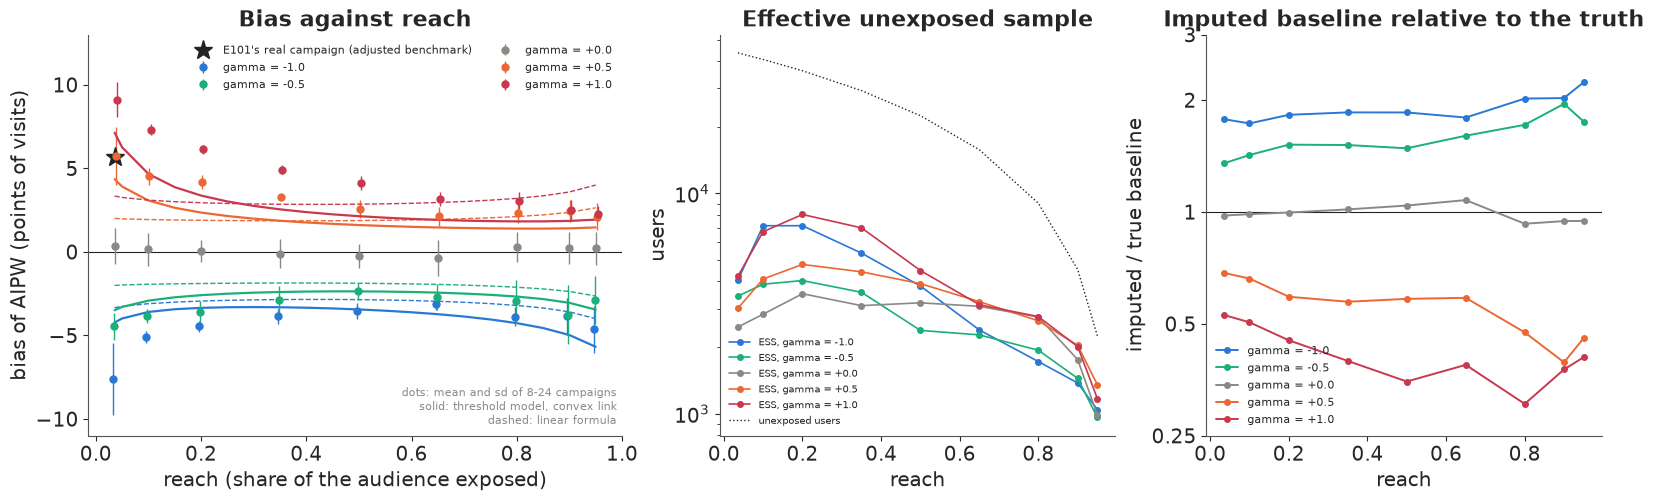

In [9]:
gcol = {-1.0: BLUE, -0.5: AQUA, 0.0: MUTED, 0.5: ORANGE, 1.0: RED}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.9), gridspec_kw={"width_ratios": [1.35, 1, 1]})
ax = axes[0]
ax.axhline(0, color=INK, lw=0.8)
for g in GAMMAS:
    s_ = pp[pp.gamma == g]
    ax.errorbar(s_.reach + g * 0.004, s_.AIPW, yerr=s_.AIPW_sd, fmt="o", color=gcol[g], ms=5, capsize=0, lw=1,
                label=f"gamma = {g:+.1f}")
    if g != 0:
        t_ = th[th.gamma == g]
        ax.plot(t_.reach, t_.convex * 100, color=gcol[g], lw=1.6)
        ax.plot(t_.reach, t_.linear * 100, color=gcol[g], lw=1, ls="--")
ax.plot([REACH_REAL], [(E101_TRUE - E101_IMPUTED) * 100], "*", color=INK, ms=14, label="E101's real campaign (adjusted benchmark)")
ax.set(xlabel="reach (share of the audience exposed)", ylabel="bias of AIPW (points of visits)",
       title="Bias against reach", ylim=(-11, 13))
ax.text(0.99, 0.02, "dots: mean and sd of 8-24 campaigns\nsolid: threshold model, convex link\ndashed: linear formula",
        transform=ax.transAxes, ha="right", va="bottom", fontsize=8, color=MUTED)
ax.legend(fontsize=8, ncol=2, loc="upper right")
ax = axes[1]
for g in GAMMAS:
    s_ = pp[pp.gamma == g]
    ax.plot(s_.reach, s_.ESS, "o-", color=gcol[g], ms=4, lw=1.2, label=f"ESS, gamma = {g:+.1f}")
ax.plot(pp[pp.gamma == 0].reach, pp[pp.gamma == 0].unexposed, color=INK, lw=1, ls=":", label="unexposed users")
ax.set(yscale="log", xlabel="reach", ylabel="users", title="Effective unexposed sample")
ax.legend(fontsize=7.5, loc="lower left")
ax = axes[2]
ax.axhline(1, color=INK, lw=0.8)
for g in GAMMAS:
    s_ = pp[pp.gamma == g]
    ax.plot(s_.reach, s_.imputed / s_.true_base, "o-", color=gcol[g], ms=4, lw=1.4, label=f"gamma = {g:+.1f}")
ax.set(xlabel="reach", ylabel="imputed / true baseline", yscale="log",
       title="Imputed baseline relative to the truth")
ax.set_yticks([0.25, 0.5, 1, 2, 3], labels=["0.25", "0.5", "1", "2", "3"])
ax.minorticks_off()
ax.legend(fontsize=8);

**The AIPW bias keeps its sign along every curve.** In the left panel every dot with $\gamma > 0$ is above zero
and every dot with $\gamma < 0$ below it, from 3.6% to 95% reach, as the threshold model says: in these
simulations, scaling up a campaign whose delivery leans one way did not flip the AIPW bias. That is one hidden
trait, five values of $\gamma$ and 8-24 replays per point, and it holds for AIPW only. IPW, run on the same
campaigns, *does* cross zero for $\gamma = +1$ between 50% and 80% reach (the table below), for reasons we come to.

**The size changes, and not the way the linear formula says.** The dashed curves are U-shaped, because the gap
in the hidden trait is. The simulated bias is not. For $\gamma = +1$ it falls from 9.1 points
at 3.6% reach to 4.1 at 50% and 2.3 at 95%; for $\gamma = +0.5$, from 5.7 to 2.6 and 2.1. The fall up to 50%
is many standard errors wide (the means' standard errors are 0.1-0.3 points, printed below the table); the
further fall to 95% is about two for $\gamma = +0.5$ and ten for $\gamma = +1$. IPW also falls from low reach. For
$\gamma < 0$ AIPW eases through the middle and deepens a little at the top: -7.6, -3.5 and -4.6 for
$\gamma = -1$; -4.5, -2.4 and -2.9 for $\gamma = -0.5$. Treat that upturn with care. For $\gamma = -1$ it is
about three standard errors, for $\gamma = -0.5$ under two, and IPW moves the *other* way, from -4.0 to -2.9
and from -2.2 to -1.0. Above about 80% reach the two estimators disagree by as much as the change itself, so the
shape there is model dependence as much as confounding.

The convex link of part A explains the asymmetry. With $\gamma > 0$ and low reach, the exposed are the top tail
of $u$, exactly where the extra visits live, so the baseline gap is large. As reach rises, the unexposed slide
into the low tail of $u$ - but users there visit at about half their predicted rate, much like users in the
middle, so a widening gap in $u$ buys almost no extra gap in visits. This is the second question's case with
media-light people who are also brand-light: the comparison group gets more extreme, and the bias in points
*shrinks*. With $\gamma < 0$ the media-light corner is where the engaged users are, and as reach leaves them
behind, the theory says the bias should grow again. The solid curves, the threshold model with the real convex
link, follow these shapes: for $\gamma = +1$ they give 7.1, 2.1 and 1.9 points at 3.6%, 50% and 95% reach, for
$\gamma = -1$, -4.2, -3.4 and -5.7. They get every sign and the broad shape, but not the size: the simulated bias is nearly twice
the theory's in the middle for $\gamma = +1$ (4.1 against 2.1) and at low reach for $\gamma = -1$ (-7.6 against
-4.2), and the theory is too deep at 95% for $\gamma = -1$. It treats $u$ as independent of the seen features,
while $u$ is only *linearly* unrelated to them: how much f8 adds, and how spread out it is, varies from one kind
of user to another, which the formula averages away.

**Overlap thins at both ends, but the far end is worse.** The middle panel shows the effective sample of the
weighted unexposed: it peaks at 20% reach for every $\gamma$ (3,500-8,000 users, printed below the table) and
falls to about 1,000 at 95%, where only 2,255 users are unexposed at all. The table puts it per exposed user: at
3.6% reach there are about two effective unexposed users for each exposed one; at 95%, each effective unexposed
user stands in for 32 to 45 exposed ones.

**In relative terms the baseline gets worse with reach, whichever the sign.** The right panel plots the imputed
baseline as a share of the true one, on a log scale so that "half" and "double" are equally far from 1. For
$\gamma = +1$ the imputed baseline is 53% of the true one at 3.6% reach and 30-41% at 80-95%; for $\gamma = -1$
it is 1.8 times the truth at 3.6% and 2.2 times at 95%. With $\gamma = 0$ it stays near 1 (the grey line).
A brand lift is reported as a ratio to that baseline. At 95% reach with $\gamma = +1$, a campaign that truly
raised visits from 3.9% to 4.9% would be reported as raising them from 1.6%: a lift of 3.1 times instead of 1.26.
So for $\gamma > 0$ the bias in points shrinks with reach while the bias in relative lift grows.

In [10]:
both = pp[pp.gamma != 0][["gamma", "reach", "AIPW", "IPW", "true_base", "imputed", "ESS", "unexposed"]].copy()
both["IPW - AIPW"] = both.IPW - both.AIPW
both["imputed / true"] = both.imputed / both.true_base
both["exposed per effective unexposed"] = (n - both.unexposed) / both.ESS
print(both[both.reach.isin([REACH_REAL, 0.2, 0.5, 0.8, 0.95])].round(2).to_string(index=False))
pk = pp.loc[pp.groupby("gamma").ESS.idxmax(), ["gamma", "reach", "ESS"]]
print("peak effective sample of the unexposed: " + ", ".join(
    f"gamma {g:+.1f}: {e:,.0f} at {r:.0%}" for g, r, e in pk.itertuples(index=False)))
print("standard error of the mean over replays at 50% and 95% reach (points):")
print(pp[pp.reach.isin([0.5, 0.95]) & (pp.gamma != 0)][["gamma", "reach", "AIPW", "AIPW_se", "IPW", "IPW_se"]]
      .round(2).to_string(index=False))

 gamma  reach  AIPW   IPW  true_base  imputed     ESS  unexposed  IPW - AIPW  imputed / true  exposed per effective unexposed
  -1.0   0.04 -7.60 -9.16       9.78    17.38 4041.44    43486.0       -1.56            1.78                             0.40
  -1.0   0.20 -4.45 -4.94       5.39     9.85 7136.21    36080.0       -0.48            1.83                             1.26
  -1.0   0.50 -3.53 -4.01       4.14     7.67 3796.78    22550.0       -0.48            1.85                             5.94
  -1.0   0.80 -3.87 -3.41       3.80     7.66 1723.33     9020.0        0.46            2.02                            20.94
  -1.0   0.95 -4.63 -2.92       3.75     8.38 1043.14     2255.0        1.70            2.23                            41.07
  -0.5   0.04 -4.46 -3.77      12.65    17.11 3417.81    43486.0        0.68            1.35                             0.47
  -0.5   0.20 -3.58 -3.37       6.92    10.50 4019.79    36080.0        0.21            1.52                          

The table also shows the second estimator. At low reach IPW and AIPW agree to within about 1.6 points, and on
the sign. As reach rises they come apart. For $\gamma = +1$, IPW falls to -0.2 points at 50% reach and -0.9 at
80% while AIPW says +4.1 and +3.1, a gap of about 4 points; for $\gamma = -0.5$ at 95%, IPW says -1.0 and
AIPW -2.9. With a few thousand unexposed users carrying the whole counterfactual, the answer depends on whether
the propensity model or the outcome model does the extrapolating, as IPW's drift in the $\gamma = 0$ check
already hinted. An analyst who used IPW on the $\gamma = +1$ campaign at 50-80% reach would have seen a
negative estimate where the confounding pushes upward: the sign they report has flipped, though not because
the hidden selection changed direction. High reach has added a modelling problem to the confounding one, and
the two can point opposite ways.

### E2 · A campaign whose bias changes sign as it grows

A single hidden trait with a fixed $\gamma$ can never flip the sign. Real campaigns change *who* they buy as
they scale. A common plan starts with **retargeting** - the people who recently engaged with the brand,
cheap and responsive - and buys reach beyond that through **prospecting**, aimed at people new to the brand.
We model it as two pools: first the 3% most engaged ($u$ plus a little noise), then the rest of the reach from
$\eta(x) - u + \varepsilon$, a prospecting buy that leans away from engaged users. The suppression list of part D
is swept too.

retarget then prospect: exposed users and the retargeting pool's share of them, by reach
reach                  0.035787  0.050000  0.100000  0.200000  0.350000  0.500000  0.650000  0.800000
exposed                 1614.00    2255.0    4510.0   9020.00  15785.00  22550.00  29315.00  36080.00
pool share of exposed      0.84       0.6       0.3      0.15      0.09      0.06      0.05      0.04
                                 AIPW         IPW      
                                 mean   std  mean   std
                       reach                           
retarget then prospect 0.035787  4.57  0.53  4.85  0.58
                       0.050000  1.30  0.46  1.92  0.50
                       0.100000 -1.74  0.45 -1.43  0.37
                       0.200000 -2.56  0.38 -2.98  0.41
                       0.350000 -2.62  0.38 -3.52  0.53
                       0.500000 -2.68  0.31 -3.60  0.46
                       0.650000 -2.35  0.51 -3.12  0.57
                       0.800000 -2.55  1.08 -

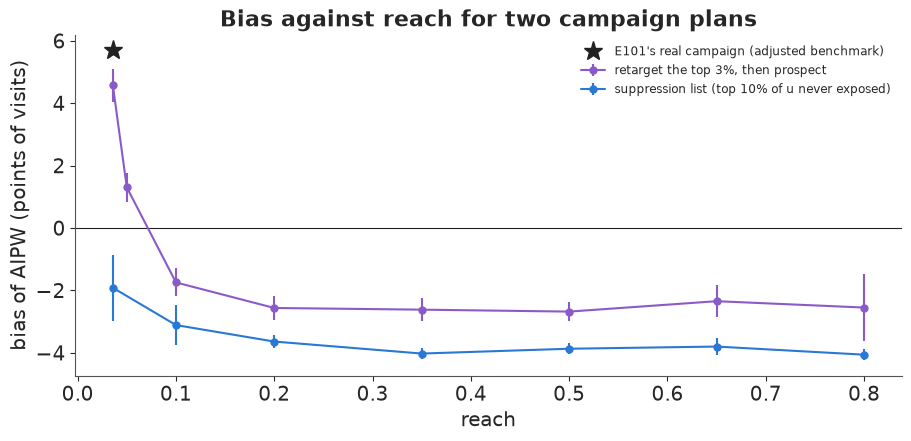

In [11]:
rs3 = np.random.default_rng(RANDOM_SEED + 3)
PLAN_REACH = [REACH_REAL, 0.05, 0.1, 0.2, 0.35, 0.5, 0.65, 0.8]


def plan(reach, rng_):
    L1 = u + 0.3 * rng_.normal(size=n)
    pool = L1 > np.quantile(L1, 0.97)                               # retargeting list: the most engaged 3%
    L = eta - 1.0 * u + rng_.normal(size=n)                         # prospecting: leans away from engagement
    L[pool] = np.inf
    d = L > np.quantile(L, 1 - reach)
    return d, (d & pool).sum() / d.sum()


plan_rows = []
for r in PLAN_REACH:
    for k in range(REPS):
        d_, share_ = plan(r, rs3)
        plan_rows.append({"reach": r, "rep": k, "pool share of exposed": share_, "exposed": d_.sum(), **analyse(d_)})
plan_runs = pd.DataFrame(plan_rows)
print("retarget then prospect: exposed users and the retargeting pool's share of them, by reach")
print(plan_runs.groupby("reach")[["exposed", "pool share of exposed"]].mean().round(2).T.to_string())
tab = pd.concat({"retarget then prospect": plan_runs.groupby("reach")[["AIPW", "IPW"]].agg(["mean", "std"]),
                 "suppression list": supp_runs.groupby("reach")[["AIPW", "IPW"]].agg(["mean", "std"])})
print((tab * 100).round(2).to_string())

fig, ax = plt.subplots(figsize=(9, 4.3))
ax.axhline(0, color=INK, lw=0.8)
for runs, col, lab in [(plan_runs, PURPLE, "retarget the top 3%, then prospect"),
                       (supp_runs, BLUE, "suppression list (top 10% of u never exposed)")]:
    g_ = runs.groupby("reach").AIPW
    ax.errorbar(g_.mean().index, g_.mean() * 100, yerr=g_.std() * 100, fmt="o-", color=col, ms=5, capsize=0, label=lab)
ax.plot([REACH_REAL], [(E101_TRUE - E101_IMPUTED) * 100], "*", color=INK, ms=14, label="E101's real campaign (adjusted benchmark)")
ax.set(xlabel="reach", ylabel="bias of AIPW (points of visits)", title="Bias against reach for two campaign plans")
ax.legend(fontsize=8.5);

The retarget-then-prospect plan starts out like E101. At 3.6% reach the exposed are mostly the retargeting pool
(84% of 1,614 users), and the bias is **+4.6 points**. At 5% reach it is +1.3; by 10% it has flipped to
**-1.7**, and from 20% to 80% it stays between -2.4 and -2.7. The plan's rules never changed. The reach decided
which hidden selection dominates the comparison: the engaged pool, whose share of the exposed falls from 84% to
4%, or the prospecting buy, which leaves engaged users on the unexposed side. The suppression list is negative at
every reach and deepens from -1.9 points at 3.6% to about -4 from 35% reach on, because the 4,510 suppressed
users are a tenth of the unexposed at low reach and half of them at 80%.

Now we can place E101's real campaign. It sits at 3.6% reach with a bias of +5.7 points against the adjusted
experiment, on the $\gamma = +0.5$ curve and at the start of the retarget-then-prospect plan. With these users, a negative bias
would have taken any of three things: delivery that leans away from engagement ($\gamma < 0$) at any reach, a
suppression list of the most engaged at any reach, or the same campaign scaled past about 10% reach with
prospecting. Scaling it up with the *same* retargeting-style delivery would not have done it for AIPW: along
$\gamma > 0$ its bias shrinks in points but stays positive, and in relative terms it gets worse.

## F · One careful Bayesian analysis of a negative-bias campaign

The sweep used point fits. To see what a full analysis reports, we take one campaign at E101's reach with
$\gamma = -0.5$ - delivery leans away from engaged users, as for ad avoiders or a prospecting buy - and give the
ads a **real effect**: each exposed user who would not have visited now visits with probability 6%. The true
effect on the exposed is known exactly, user by user. We also build its mirror image, the same campaign with
$\gamma = +0.5$, from the same noise. A vendor would analyse a sample of respondents; we analyse the whole
audience of 45,100, which gives the propensity analysis every advantage it can have.

In [12]:
rs4 = np.random.default_rng(RANDOM_SEED + 4)
eps_ref = rs4.normal(size=n)
lift_draw = rs4.random(n) < 0.06                                    # who the ad would turn into a visitor
worlds = {}
for name, g in [("negative world (gamma = -0.5)", -0.5), ("positive world (gamma = +0.5)", 0.5)]:
    L = eta + g * u + eps_ref
    d = L > np.quantile(L, 1 - REACH_REAL)
    y = np.where(d & lift_draw, 1.0, Y0)                            # observed visit: the ad works for some
    worlds[name] = {"d": d, "y": y, "S": np.arange(n), "att": (y[d] - Y0[d]).mean(), "base": Y0[d].mean()}
    print(f"{name}: {d.sum():,} exposed; true no-ad visit rate of the exposed {Y0[d].mean():.4f}, with ads "
          f"{y[d].mean():.4f}; TRUE effect on the exposed {worlds[name]['att'] * 100:.2f} points")

negative world (gamma = -0.5): 1,614 exposed; true no-ad visit rate of the exposed 0.1289, with ads 0.1760; TRUE effect on the exposed 4.71 points
positive world (gamma = +0.5): 1,614 exposed; true no-ad visit rate of the exposed 0.1958, with ads 0.2435; TRUE effect on the exposed 4.77 points


In [13]:
NEG, POS = list(worlds)
w_ = worlds[NEG]
S, Zs, Ds, Ys = w_["S"], Zp[w_["S"]], w_["d"][w_["S"]].astype(int), w_["y"][w_["S"]]
coords = {"feature": SEEN_NAMES}


def propensity_model(Z, d):
    with pm.Model(coords=coords) as m:
        a = pm.Normal("a", special.logit(d.mean()), 1.0)
        b_lin = pm.Normal("b_lin", 0.0, 0.5, dims="feature")
        tau_q = pm.HalfNormal("tau_q", 0.5)
        b_quad = pm.Normal("b_quad", 0.0, tau_q, dims="feature")
        pm.Bernoulli("exposed", logit_p=a + Z[:, :11] @ b_lin + Z[:, 11:] @ b_quad, observed=d)
    return m


def outcome_model(Z, y):
    with pm.Model(coords=coords) as m:
        a = pm.Normal("a", special.logit(max(y.mean(), 1e-3)), 1.5)
        b_lin = pm.Normal("b_lin", 0.0, 0.5, dims="feature")
        b_quad = pm.Normal("b_quad", 0.0, 0.5, dims="feature")
        pm.Bernoulli("y", logit_p=a + Z[:, :11] @ b_lin + Z[:, 11:] @ b_quad, observed=y)
    return m


def draws_of(idata, k=400):
    po = az.extract(idata, var_names=["a", "b_lin", "b_quad"], num_samples=k, random_seed=RANDOM_SEED)
    B = np.concatenate([po["b_lin"].values, po["b_quad"].values], 0)
    return po["a"].values[None, :] + Zs @ B                         # linear predictor on the file, (rows, draws)


fits = {}
for lab, model, rows_ in [("propensity", propensity_model(Zs, Ds), len(Ds)),
                          ("outcome", outcome_model(Zs[Ds == 0], Ys[Ds == 0]), int((Ds == 0).sum()))]:
    t0 = time.time()
    with model:
        idt = pm.sample(tune=400, draws=500, random_seed=RANDOM_SEED, progressbar=False, nuts={"adaptation": "low_rank"})  # E101's settings
    sm = az.summary(idt, round_to=4)
    print(f"{lab:10s} model on {rows_:,} rows: {time.time() - t0:.0f} s, "
          f"divergences {int(idt.sample_stats['diverging'].sum())}, max r_hat {sm['r_hat'].max():.3f}, "
          f"min bulk ESS {sm['ess_bulk'].min():.0f}")
    fits[lab] = draws_of(idt)
    del idt
eta_s = fits["propensity"]                                          # file-scale log-odds of exposure
m0_s = special.expit(fits["outcome"])

propensity model on 45,100 rows: 56 s, divergences 0, max r_hat 1.007, min bulk ESS 3477


outcome    model on 43,486 rows: 43 s, divergences 0, max r_hat 1.007, min bulk ESS 4280


The models are E101's, on the eleven seen features: the propensity model with N(0, 0.5) slopes and a shared
scale for the squares, the outcome model on the 43,486 unexposed users. We keep E101's 400 tuning and 500
drawn steps per chain, which hold each fit on 45,000 rows under a minute and still leave thousands of effective
draws. Both fits are clean: no divergences, r_hat at most 1.007, at least 3,400 effective draws. As in E101 we push the posterior
through the estimators with a **cut** (the propensity model never sees the outcome) and the **Bayesian
bootstrap** for the users: 400 draws, each pairing a propensity draw, an outcome-model draw and a set of
Exponential(1) weights over users, with the same 0.99 cap on the propensity.

In [14]:
def estimates(y, d, w, m0, g):
    t, un = d == 1, d == 0
    y1 = np.average(y[t], weights=g[t])
    return {"IPW": y1 - np.average(y[un], weights=g[un] * w[un]),
            "AIPW": np.average(y[t] - m0[t], weights=g[t]) - np.average(y[un] - m0[un], weights=g[un] * w[un])}


rows = []
for j in range(400):
    gb = rs4.exponential(size=len(S))
    rows.append(estimates(Ys, Ds, att_weights(eta_s[:, j]), m0_s[:, j], gb))
post_neg = pd.DataFrame(rows)
truth_neg = w_["att"]
print(f"TRUE effect on the exposed {truth_neg * 100:.2f} points")
for k in ("IPW", "AIPW"):
    v = post_neg[k] * 100
    print(f"{k:5s}: posterior mean {v.mean():+.2f}, 90% interval {v.quantile(0.05):+.2f} to {v.quantile(0.95):+.2f}; "
          f"P(effect > 0) {np.mean(v > 0):.2f}; P(effect > truth) {np.mean(v > truth_neg * 100):.3f}")

TRUE effect on the exposed 4.71 points
IPW  : posterior mean +0.52, 90% interval -2.01 to +2.90; P(effect > 0) 0.66; P(effect > truth) 0.000
AIPW : posterior mean +0.07, 90% interval -1.84 to +2.03; P(effect > 0) 0.54; P(effect > truth) 0.000


The ads worked. They raised the exposed users' visit rate from 12.9% to 17.6%, a true effect of **4.7 points**,
a lift of more than a third. The Bayesian analysis reports **+0.1 points** by AIPW (90% interval -1.8 to +2.0)
and +0.5 by IPW (-2.0 to +2.9), and not one of its 400 posterior draws reaches the truth. The report a brand
manager would receive is "no detectable effect", with the probability of a positive effect close to a coin
flip (0.54 for AIPW). That is the practical face of a negative bias: on a campaign that works it does not look
like an error, it looks like a disappointing campaign. Only when it overshoots zero, as in the placebo runs, does
the result look odd, since ads rarely make people *less* likely to visit; a null or modest lift raises no flag.

Could the analyst have noticed? We run the same diagnostics as E101 on both worlds, with posterior-mode fits
for speed: balance of the seen features after weighting, calibration of the propensity model, the effective
sample of the weighted unexposed, and the estimate. The last row is the one the analyst can never compute,
the balance of the hidden trait.

In [15]:
def diagnostics(w):
    S_, d_, y_ = w["S"], w["d"][w["S"]].astype(float), w["y"][w["S"]]
    Z_ = Zp[S_]
    Z1_ = np.column_stack([np.ones(len(Z_)), Z_])
    e_ = Z1_ @ fit_map(Z_, d_, a0=special.logit(d_.mean()))
    t, un = d_ == 1, d_ == 0
    wt = att_weights(e_)
    m0 = special.expit(Z1_ @ fit_map(Z_[un], y_[un], a0=special.logit(y_[un].mean())))
    Xs_ =X[ctl][S_][:, SEEN]
    sd_ = np.sqrt((Xs_[t].var(0) + Xs_[un].var(0)) / 2)
    smd_after = (Xs_[t].mean(0) - np.average(Xs_[un], axis=0, weights=wt[un])) / sd_
    p_ = special.expit(e_)
    b_ = pd.qcut(p_, 20, labels=False, duplicates="drop")
    c_ = pd.DataFrame({"p": p_, "d": d_}).groupby(b_).agg(p=("p", "mean"), d=("d", "mean"), n=("d", "size"))
    miss = int(np.sum(np.abs(c_.d - c_.p) > 1.645 * np.sqrt(c_.p * (1 - c_.p) / c_.n)))
    uu = u[S_]
    return {"max |SMD| seen features, before": np.max(np.abs((Xs_[t].mean(0) - Xs_[un].mean(0)) / sd_)),
            "max |SMD| seen features, after weighting": np.max(np.abs(smd_after)),
            "calibration bins missed (of 20)": miss,
            "ESS of weighted unexposed": wt[un].sum() ** 2 / (wt[un] ** 2).sum(),
            "AIPW estimate (points)": 100 * (np.mean(y_[t] - m0[t]) - np.average(y_[un] - m0[un], weights=wt[un])),
            "true effect (points)": 100 * w["att"],
            "hidden: SMD of u after weighting": (uu[t].mean() - np.average(uu[un], weights=wt[un])) / uu.std()}


diag = pd.DataFrame({name: diagnostics(w) for name, w in worlds.items()})
print(diag.round(3).to_string())

                                          negative world (gamma = -0.5)  positive world (gamma = +0.5)
max |SMD| seen features, before                                   1.457                          1.447
max |SMD| seen features, after weighting                          0.080                          0.087
calibration bins missed (of 20)                                  10.000                          7.000
ESS of weighted unexposed                                      3220.354                       2585.669
AIPW estimate (points)                                            0.104                         12.004
true effect (points)                                              4.709                          4.771
hidden: SMD of u after weighting                                 -1.090                          1.133


The diagnostics cannot tell the two worlds apart. Before weighting, exposed and unexposed users differ by 1.46
and 1.45 standard deviations on the most imbalanced seen feature; after weighting the largest gap is 0.080 in
one world and 0.087 in the other, both inside the usual 0.1 band. Calibration misses 10 and 7 of 20 bins (a
logistic model is not the probit-like delivery rule, just as it failed on E101's real exposures), and the
effective samples are 3,200 and 2,600 users. Yet one analysis says 0.1 points against a truth of 4.7, and the
other **12.0** against 4.8. The last row is the reason, and the analyst never sees it: after weighting, the
hidden trait is still 1.1 standard deviations off, downward in one world and upward in the other. Every check
the analyst can run is a check on the features they have.

## G · Can the data tell the sign?

E101 put the hidden bias into a model: the true no-ad rate of the exposed differs from the imputed one by a
log odds ratio $\delta$,

$$\operatorname{logit} q_{\text{true}} = \operatorname{logit} q_{\text{imputed}} + \delta,\qquad \tau = p_1 - q_{\text{true}},$$

and since the exposed users' no-ad outcome is never observed, nothing in the data touches $\delta$. We fit it
for both worlds in one PyMC model, with the imputed baseline's logit as a parameter of its own, measured with
noise (mean and sd of
its logit from 400 Bayesian-bootstrap replays of the posterior-mode analysis), the exposed rate from its
counts, and two priors on $\delta$: a symmetric $N(0, 0.5)$, and a one-sided $|N(0, 0.5)|$ that encodes the
lesson an analyst might take from E101 and from Gordon et al. - "propensity methods overstate". The true
baseline is then the imputed one shifted by $\delta$, so the sampler never has to explore a ridge on which the
two trade off against each other.

In [16]:
def boot_baseline(w, B=400):
    S_, d_, y_ = w["S"], w["d"][w["S"]].astype(float), w["y"][w["S"]]
    Z_ = Zp[S_]
    Z1_ = np.column_stack([np.ones(len(Z_)), Z_])
    e_ = Z1_ @ fit_map(Z_, d_, a0=special.logit(d_.mean()))
    t, un = d_ == 1, d_ == 0
    wt = att_weights(e_)
    m0 = special.expit(Z1_ @ fit_map(Z_[un], y_[un], a0=special.logit(y_[un].mean())))
    out = []
    for _ in range(B):
        gb = rs4.exponential(size=len(S_))
        y1 = np.average(y_[t], weights=gb[t])
        aipw = np.average(y_[t] - m0[t], weights=gb[t]) - np.average(y_[un] - m0[un], weights=gb[un] * wt[un])
        out.append(y1 - aipw)                                       # imputed no-ad rate of the exposed
    return special.logit(np.array(out))


WN = list(worlds)
lq = np.array([boot_baseline(worlds[k]) for k in WN])
lq_mu, lq_sd = lq.mean(1), lq.std(1)
n1 = np.array([worlds[k]["d"].sum() for k in WN])
y1c = np.array([int(worlds[k]["y"][worlds[k]["d"]].sum()) for k in WN])
true_delta = np.array([special.logit(worlds[k]["base"]) for k in WN]) - lq_mu
PRIORS = ["symmetric", "one-sided (overstates)"]
with pm.Model(coords={"world": ["negative", "positive"], "prior": PRIORS}) as sens:
    p1 = pm.Beta("p1", 1.0, 1.0, dims="world")
    pm.Binomial("y1", n=n1, p=p1, observed=y1c, dims="world")
    lq_imp = pm.Normal("logit_q_imputed", -2.0, 2.0, dims="world")  # what the propensity analysis estimates
    pm.Normal("imputed", mu=lq_imp, sigma=lq_sd, observed=lq_mu, dims="world")
    d_sym = pm.Normal("d_sym", 0.0, 0.5, dims="world")
    d_pos = pm.HalfNormal("d_pos", 0.5, dims="world")
    delta = pm.Deterministic("delta", pm.math.stack([d_sym, d_pos]), dims=("prior", "world"))
    lq_true = pm.Deterministic("logit_q", lq_imp[None, :] + delta, dims=("prior", "world"))
    pm.Deterministic("att", p1 - pm.math.invlogit(lq_true), dims=("prior", "world"))
    idata_sens = pm.sample(random_seed=RANDOM_SEED, progressbar=False)
print(f"divergences {int(idata_sens.sample_stats['diverging'].sum())}; "
      f"max r_hat {az.summary(idata_sens, var_names=['att'], round_to=4)['r_hat'].max():.3f}")
rows = []
for i, wname in enumerate(["negative", "positive"]):
    for pr in PRIORS:
        dl = idata_sens.posterior["delta"].sel(prior=pr, world=wname).values.ravel()
        at = idata_sens.posterior["att"].sel(prior=pr, world=wname).values.ravel() * 100
        rows.append({"world": wname, "prior on delta": pr, "true delta": true_delta[i], "P(delta > 0)": np.mean(dl > 0),
                     "sd(delta)": dl.std(), "att mean": at.mean(), "att 5%": np.percentile(at, 5),
                     "att 95%": np.percentile(at, 95), "true att": worlds[WN[i]]["att"] * 100})
print(pd.DataFrame(rows).round(3).to_string(index=False))


def e_value(rr):
    rr = np.where(rr < 1, 1 / rr, rr)
    return rr + np.sqrt(rr * (rr - 1))


for i, k in enumerate(WN):
    p1o = worlds[k]["y"][worlds[k]["d"]].mean()
    q_imp = special.expit(lq_mu[i])
    print(f"{k}: observed risk ratio {p1o / q_imp:.2f} (E-value {e_value(p1o / q_imp):.2f}); bias factor to the "
          f"truth {q_imp / worlds[k]['base']:.2f} (E-value {e_value(q_imp / worlds[k]['base']):.2f})")

divergences 0; max r_hat 1.002
   world         prior on delta  true delta  P(delta > 0)  sd(delta)  att mean  att 5%  att 95%  true att
negative              symmetric      -0.359         0.486      0.502    -0.833 -15.025    9.247     4.709
negative one-sided (overstates)      -0.359         1.000      0.302    -6.824 -19.162    0.178     4.709
positive              symmetric       0.549         0.508      0.503    10.941  -0.745   19.048     4.771
positive one-sided (overstates)       0.549         1.000      0.297     6.575  -3.441   12.584     4.771
negative world (gamma = -0.5): observed risk ratio 1.01 (E-value 1.09); bias factor to the truth 1.36 (E-value 2.05)
positive world (gamma = +0.5): observed risk ratio 1.98 (E-value 3.36); bias factor to the truth 0.63 (E-value 2.55)


The posterior of $\delta$ is its prior in both worlds. Under the symmetric prior, $P(\delta > 0)$ is about one
half in each and its sd is about 0.5, the prior's, although the true $\delta$ is -0.36 in the negative world and
+0.55 in the positive one. The honest sensitivity interval is therefore wide - roughly -15 to +9 points in the
negative world and -1 to +19 in the positive one - and it covers the truth in both, but it is centred on the
biased estimate and nothing in it says which way to lean.

The one-sided prior is the dangerous one, because it encodes a true lesson from the wrong campaign. In the
positive world it helps, pulling the estimate from about 11 points down to about 6.6, nearer the truth of 4.8.
In the negative world it pushes the wrong way, from about -1 to about -6.8 points, with a 90% interval that
ends near +0.2 and so **excludes the true +4.7**. Borrowing E101's direction for a campaign that chose its
audience differently turns a bad estimate into a worse one.

The E-values say the same in their own units. In the negative world the observed risk ratio is 1.01, so an
almost nonexistent confounder could explain the association away (E-value 1.09), while closing the gap to the
truth needs one of strength 2.05 pointing the other way. In the positive world the numbers are 3.36 and 2.55. An
E-value measures how strong a hidden confounder must be, never which way it points. The direction is an
assumption about how the campaign was delivered, not something the data can supply.

## H · What this means for a brand lift study

The brand manager in E101 asked whether the ads worked. This notebook adds a harder question: if the study has
no holdout, which way is it wrong?

**The study itself cannot say.** The sign of the bias is set by how delivery related to the outcome beyond the
measured features. Retargeting and in-market targeting push it up; suppression lists, prospecting buys, reach
extensions and ad avoidance push it down; a real campaign mixes them in proportions that change with its reach.
Balance, calibration, overlap and agreement between estimators look the same either way, and a sensitivity
analysis returns its prior.

**High reach is the worst case for relative lift and for overlap.** At 95% reach the unexposed are the 5% of the
audience the campaign could not or would not reach. Each effective comparison user stands in for 32-45 exposed
ones, the imputed baseline is off by a factor of 1.75 to 2.4 in relative terms in every world where delivery
used the hidden trait, and IPW and AIPW disagree by up to 2 points there and 4 points at 50-80% reach. It is not
the worst case for the bias in points: with retargeting-like delivery that shrank with reach, because the visits
live in the top tail of the hidden trait. Reach campaigns - brand campaigns, the ones that commission brand lift
studies - are exactly the ones with the thinnest overlap and the least reliable baseline ratio.

**What to do.** Keep a randomised holdout, even a small one; it is the only thing in this notebook that knows
the sign. Better, use a ghost-ad or PSA control (Johnson, Lewis & Nubbemeyer 2017), which also finds the control
users who *would* have been exposed and so removes most of the noise that makes small holdouts painful (E101,
part H). Where the platform cannot hold out users, a geographic or time-based holdout still beats an unexposed
group. If no holdout is possible, report the observational estimate with a sensitivity interval for $\delta$
that stays two-sided unless the campaign's own delivery rules justify a direction: list the ingredients -
retargeting pools, suppression and exclusion lists, prospecting share, the channels ad avoiders escape - and
write down which way each pushes before looking at the estimate. Never borrow the direction from another
campaign. Calibrate the interval's width on past campaigns of the same kind and reach that did have a holdout.
And treat a null or modest lift from a reach campaign with suppression lists with particular suspicion: it may
be a working campaign compared with its own best customers.

In [17]:
print(f"total run time {time.time() - T_START:.0f} s")

total run time 154 s


## Summary

- **The bias is one number: true minus imputed baseline, and its sign is the sign of hidden targeting times the
  outcome.** On 45,100 real control users with simulated delivery and a true effect of zero, delivery leaning
  toward a hidden engagement trait overstated the effect by 5.7-9.1 points of visits at E101's 3.6% reach;
  leaning away understated it by 4.5-7.6 points. A hidden trait with f8's private information at $\gamma = +0.5$
  reproduces E101's +5.7 (measured against E101's adjusted experiment; unadjusted, E101's visit bias would be
  negative). The limit: one hidden trait from an anonymised feature, one outcome, one audience.
- **Negative bias is ordinary.** Suppression lists (-1.9 points at 3.6% reach, about -4 from 35% on),
  prospecting and reach buys, ad avoiders and, in surveys, media-light respondents loyal to established brands
  all put high-baseline people on the unexposed side.
- **In these simulations reach did not flip the AIPW bias of a fixed delivery rule, but a growing campaign can
  flip.** Along every $\gamma$ curve the AIPW sign held from 3.6% to 95% reach; IPW's estimate crossed zero for
  $\gamma = +1$ at 50-80% reach (-0.2 and -0.9). A retarget-then-prospect plan went from +4.6 points at 3.6% to
  -1.7 at 10% and about -2.6 beyond.
- **The threshold formula explains the sign and the U-shaped gap in the hidden trait, not the size.** The gap
  $\phi(t)/[\Phi(t)(1-\Phi(t))]$, at the standardised bar $t$, is 1.60 sd at 50% reach and 2.17 at 5% or 95%.
  Because visits are concentrated in the top tail of the trait, the bias in points shrank with reach when the
  media-light were brand-light (9.1 to 2.3 for $\gamma = +1$, 5.7 to 2.1 for $\gamma = +0.5$). When they were
  brand-heavy it eased through the middle, and the small upturn at high reach depended on the estimator. A
  threshold model with the real convex link got every sign and was off by up to a factor of about two in size.
- **High reach is the worst case for relative lift and overlap, not for points.** At 95% reach each effective
  unexposed user stood in for 32-45 exposed ones and the imputed baseline was off by a factor of 1.75-2.4 wherever
  delivery used the hidden trait (41% of the truth for $\gamma = +1$, 2.2 times it for $\gamma = -1$); from 50%
  reach up IPW and AIPW disagreed by as much as 4.3 points.
- **A careful Bayesian analysis reported a working campaign as useless.** With a true effect of 4.7 points, a
  full PyMC propensity analysis (no divergences) said +0.1 (90% interval -1.8 to +2.0). The same analysis with
  point fits balanced the seen features within 0.08 and, in the mirror-image world, said 12.0 against 4.8; balance
  and overlap looked the same in both worlds, and calibration missed 10 and 7 of 20 bins in both.
- **The data cannot tell the sign.** The bias parameter's posterior equalled its prior in both worlds
  ($P(\delta > 0) \approx 0.5$); E-values give strength, not direction; a one-sided prior borrowed from E101 drove
  the negative world's interval away from the truth.

## Try it yourself

1. **Hide a different feature.** Rebuild the hidden trait from f9 instead of f8 and rerun the sweep. Is its link
   to visits as convex, and does the bias against reach keep the same asymmetric shape?
2. **Move the retargeting pool.** Make the retarget-then-prospect plan's pool 1% or 10% of the audience instead of
   3%, and find the reach at which the bias changes sign. Is it where the pool stops being most of the exposed?
3. **A Bayesian model of bias against reach.** Treat the eight replays of each setting as data and fit, in PyMC,
   bias$(\gamma, r) = \lambda \times$ (convex threshold curve) plus noise, with one $\lambda$ per sign of
   $\gamma$. Is $\lambda$ above 1, as part E suggests, and does a term in $\log[r/(1-r)]$ earn its place?